## Logistic Regression
### Pima Indians Diabetes Dataset
- **Course:** Statistics and Machine Learning
- **Format:** Individual task
- **Overview:** You will train, evaluate, and visualize ONE model. Afterwards you will present your results to your (3-4) groupmates and compare them.

---

### Fairness note
All 4-5 exercises in this group project use:
- the **same dataset**
- the **same cleaning steps**
- the **same train/test split** (fixed `random_state=42`, `test_size=0.2`)
- the **same number of required evaluation metrics** (4)
- the **same number of required visualizations** (3)

- > This is intentional! It means when you compare results with your groupmates later, any differences you see come from the **algorithm itself**, not from different data handling. 
- > Important Note: Do not change the split or the cleaning steps described below, even if you think another approach would work better as consistency across the group matters more here than optimizing your individual score.

---



## 1. Dataset

**File:** `diabetes.csv` in [Pima Indians Diabetes Dataset](https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv)

**Columns:**

| Column | Meaning |
|---|---|
| Pregnancies | Number of pregnancies |
| Glucose | Plasma glucose concentration |
| BloodPressure | Diastolic blood pressure (mm Hg) |
| SkinThickness | Triceps skinfold thickness (mm) |
| Insulin | 2-Hour serum insulin |
| BMI | Body mass index |
| DiabetesPedigreeFunction | Diabetes likelihood based on family history |
| Age | Age in years |
| Outcome | 0 = no diabetes, 1 = diabetes |

Place `diabetes.csv` in the same folder as this notebook before you start.


## 2. Data Preparation (required -> identical for all 4-5 exercises)

Follow these steps **in order**. Do not skip or reorder any step.

1. **Load the dataset** with pandas and display `.shape`, `.head()`, `.info()`, and `.describe()`.
2. **Fix hidden missing values.** In this dataset, the columns `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` use `0` to represent a missing value (a person cannot have 0 glucose or 0 BMI). Replace `0` with `NaN` in exactly these 5 columns only. Do **not** touch `Pregnancies`, `Age`, `DiabetesPedigreeFunction`, or `Outcome` -> a value of 0 is valid for these.
3. **Impute missing values** using the **median** of each column (fit the median on the training set only, after the split in Step 4, then apply it to both train and test -> this avoids data leakage).
4. **Define X and y.** Your target `y` is **Outcome** (0 = no diabetes, 1 = diabetes). Your features `X` are all remaining columns.
5. **Keep all other columns** as features -> no columns need to be dropped for this exercise.
6. **Report** how many missing values were found per column before imputation (one short printed table or Series is enough).


In [167]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from matplotlib import pyplot as plt
import seaborn as sns

import numpy as np

DATA_DIR = 'diabetes.csv'

df = pd.read_csv(DATA_DIR)
df['DiabetesStatus'] = df['Outcome'].map({0: 'Non-Diabetic', 1: 'Diabetic'})

print(f'Dataset loaded: {df.shape[0]} rows x {df.shape[1]} columns')


Dataset loaded: 768 rows x 10 columns


In [168]:
print('Shape:', df.shape)

print('\nData types:')
print(df.dtypes)


Shape: (768, 10)

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
DiabetesStatus               object
dtype: object


In [169]:
# --- Explicit missing values ---
print('Explicit missing values (NaN):')
print(df.isnull().sum())

# --- Implicit missing values ---
suspect_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print('\nZero counts in clinically implausible columns:')
print((df[suspect_cols] == 0).sum())


Explicit missing values (NaN):
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
DiabetesStatus              0
dtype: int64

Zero counts in clinically implausible columns:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [170]:

df_clean = df.copy()
df_clean[suspect_cols] = df_clean[suspect_cols].replace(0, np.nan)
print('\nNaN counts after replacing zeros:')
print(df_clean[suspect_cols].isna().sum())
print('These are now considered explicit missing values.')


NaN counts after replacing zeros:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
These are now considered explicit missing values.


In [171]:
target = 'Outcome'


numerical_features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
categorical_features = ['Outcome']

df_manual = df.copy()
for col in numerical_features:
    df_manual[col] = df_manual[col].fillna(df_manual[col].median())
    
X = df_manual[numerical_features]
y = df_manual[target]
# for col in categorical_features:
#     df_manual[col] = df_manual[col].fillna(df_manual[col].mode()[0])
print('\nNaN counts after imputing:')
print(df_manual.isna().sum())
print('Display dataset')
print(df_manual.head())



NaN counts after imputing:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
DiabetesStatus              0
dtype: int64
Display dataset
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome DiabetesStatus  
0                     0.627   50        1       Diabetic  
1                     0.351   31        0   Non-Diabetic  
2                     0.672   32 

## 3. Train/Test Split (required -> identical for all 4-5 exercises)

- Use `train_test_split` from `sklearn.model_selection`.
- `test_size=0.2`
- `random_state=42`
- For classification tasks: use `stratify=y` so the class balance is preserved in both sets.
- Print the shape of `X_train`, `X_test`, `y_train`, `y_test` to confirm the split.

**Do not change these settings.** They must be identical across all 4-5 group members so that your final comparison is fair.


In [172]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)
print(y_train.shape)
print(y_test.shape)
print('Train labels:', y_train.value_counts())
print('Test labels:', y_test.value_counts())

Train shape: (614, 8)
Test shape: (154, 8)
(614,)
(154,)
Train labels: Outcome
0    400
1    214
Name: count, dtype: int64
Test labels: Outcome
0    100
1     54
Name: count, dtype: int64


## 4. Libraries

```
pandas
numpy
matplotlib
seaborn
sklearn.model_selection (train_test_split)
sklearn.preprocessing (StandardScaler)
sklearn.linear_model (LogisticRegression)
sklearn.metrics (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)
```

> **Scaling:** Apply `StandardScaler` to the features. Fit the scaler on `X_train` only, then transform both `X_train` and `X_test`.


In [173]:
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)
# print('Train shape after scaling:', X_train_scaled.shape)
# print('Test shape after scaling:', X_test_scaled.shape)
print(X_train.head())

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Train shape after scaling:', X_train_scaled.shape)
print('Test shape after scaling:', X_test_scaled.shape)


     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
353            1       90             62             12       43  27.2   
711            5      126             78             27       22  29.6   
373            2      105             58             40       94  34.9   
46             1      146             56              0        0  29.7   
682            0       95             64             39      105  44.6   

     DiabetesPedigreeFunction  Age  
353                     0.580   24  
711                     0.439   40  
373                     0.225   25  
46                      0.564   29  
682                     0.366   22  
Train shape after scaling: (614, 8)
Test shape after scaling: (154, 8)


## 5. Training & Hyperparameters

1. Train a baseline `LogisticRegression()` model (default threshold = 0.5) on the scaled training data.
2. Extract the **predicted probabilities** (`predict_proba`) for the test set, not just the class labels.
3. **Threshold experiment:** using the predicted probabilities, manually generate class predictions at **3 thresholds**: 0.3, 0.5, and 0.7. For each threshold, compute Precision and Recall. Present this as a small table (rows = threshold, columns = Precision / Recall).


In [174]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

LogisticRegression()

In [175]:
y_proba = model.predict_proba(X_test_scaled)[:, 1]

In [176]:
thresholds = [0.3, 0.5, 0.7]
results = []

for t in thresholds:
    y_pred_t = (y_proba >= t).astype(int)
    precision = precision_score(y_test, y_pred_t)
    recall = recall_score(y_test, y_pred_t)
    results.append({'Threshold': t, 'Precision': precision, 'Recall': recall})

threshold_df = pd.DataFrame(results).set_index('Threshold')
print(threshold_df)

           Precision    Recall
Threshold                     
0.3         0.594595  0.814815
0.5         0.608696  0.518519
0.7         0.714286  0.370370


## 6. Evaluation & Visualization

**Required metrics** (compute at the default 0.5 threshold, on the test set):
- Accuracy
- Precision
- Recall
- F1-score

**Required visualizations** (3 total):
1. **Confusion matrix heatmap** (at threshold = 0.5), with axis labels for actual vs. predicted class.
2. **Predicted probability distribution** -> a histogram of predicted probabilities, split by true class (two overlapping distributions: one for Outcome=0, one for Outcome=1).
3. **Threshold trade-off plot** -> Precision and Recall (y-axis) plotted against threshold (x-axis, at least the 3 values from Section 5), as two lines on the same chart.


In [177]:
# cnf_matrix = metrics.confusion_matrix(y_test, y_pred_t)
# cnf_matrix

y_pred = model.predict(X_test_scaled)  # uses default 0.5 threshold

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f'Accuracy:  {accuracy:.3f}')
print(f'Precision: {precision:.3f}')
print(f'Recall:    {recall:.3f}')
print(f'F1-score:  {f1:.3f}')


Accuracy:  0.714
Precision: 0.609
Recall:    0.519
F1-score:  0.560


In [178]:
coef_df = pd.DataFrame({
    'Feature': numerical_features,
    'Coefficient': model.coef_[0]
}).sort_values('Coefficient', key=abs, ascending=False)

print(coef_df)

                    Feature  Coefficient
1                   Glucose     1.144151
5                       BMI     0.713893
0               Pregnancies     0.373178
6  DiabetesPedigreeFunction     0.255527
2             BloodPressure    -0.197637
7                       Age     0.184179
4                   Insulin    -0.127308
3             SkinThickness     0.066535


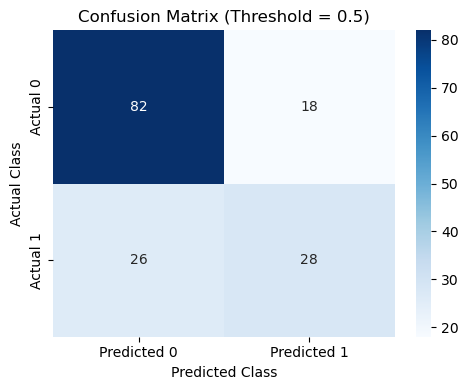

In [179]:
# from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Confusion Matrix (Threshold = 0.5)')
plt.tight_layout()
plt.show()

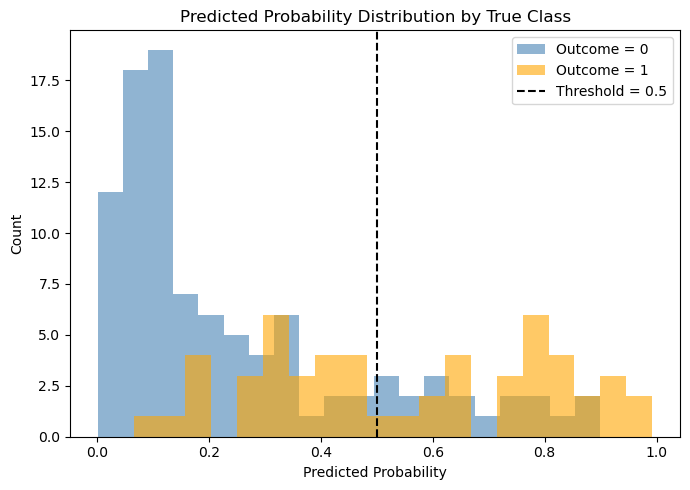

In [180]:
plt.figure(figsize=(7, 5))
plt.hist(y_proba[y_test == 0], bins=20, alpha=0.6, label='Outcome = 0', color='steelblue')
plt.hist(y_proba[y_test == 1], bins=20, alpha=0.6, label='Outcome = 1', color='orange')
plt.axvline(0.5, color='black', linestyle='--', label='Threshold = 0.5')
plt.xlabel('Predicted Probability')
plt.ylabel('Count')
plt.title('Predicted Probability Distribution by True Class')
plt.legend()
plt.tight_layout()
plt.show()

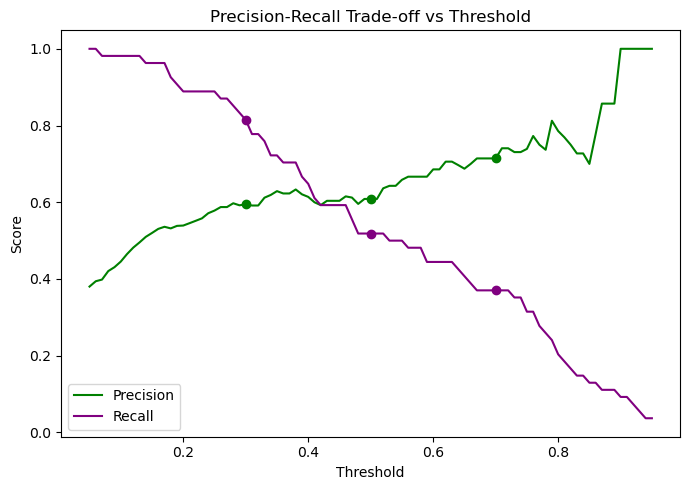

In [181]:

fine_thresholds = np.arange(0.05, 0.96, 0.01)
precisions = []
recalls = []

for t in fine_thresholds:
    y_pred_t = (y_proba >= t).astype(int)
    precisions.append(precision_score(y_test, y_pred_t, zero_division=0))
    recalls.append(recall_score(y_test, y_pred_t, zero_division=0))

plt.figure(figsize=(7, 5))
plt.plot(fine_thresholds, precisions, label='Precision', color='green')
plt.plot(fine_thresholds, recalls, label='Recall', color='purple')
plt.scatter([0.3, 0.5, 0.7], 
            [precision_score(y_test, (y_proba >= t).astype(int)) for t in [0.3, 0.5, 0.7]],
            color='green', zorder=5)
plt.scatter([0.3, 0.5, 0.7], 
            [recall_score(y_test, (y_proba >= t).astype(int)) for t in [0.3, 0.5, 0.7]],
            color='purple', zorder=5)
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall Trade-off vs Threshold')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Reflection Questions (write short answers, 1–3 sentences each)

1. Which features seemed most important for Logistic Regression, and how do you know (from your visualizations or model output)?
Glucose had a coefficient of 1.144151 by the model, which was the highest. By this, we can say that Glucose had the most influence and seems to be the most important for the Logistic Regression

2. What was the effect of the hyperparameter(s) you tuned in Section 5? Did performance improve, get worse, or barely change?
With a threshold of 0.3, we had a precision of 0.594595, and a higher recall of 0.814815
With a threshold of 0.7, we had the inverse effect, with precision: 0.714286, and recall: 0.370370
This shows us a significant drop in performance against recall, when threshold is increased.

3. Look at your error/residual or confusion matrix visualization -> where does the model struggle most? Any patterns?
Per the confusion matrix:
TP: 82
FN: 18
FP: 26
TN: 28
The highest number of wrongful predictions shown by the confusion matrix is the FP. (Classifying non-diabetic as diabetic wrongfully). So this is where the model struggles most.

4. If you had to explain this model to someone who has never studied ML, what is the one-sentence idea behind it?
This is a Logistic Regression, and what it basically does is to learn the behaviour/traits (health measuremeants in this case) of previously confirmed diabetic patients, and then compare the newer patient's health measurements to identify similarities, then project a probability based on the similarities.

5. Look at the predicted probability distributions by class -> do the two classes separate cleanly, or is there a lot of overlap? What does that tell you about how confident the model is?
There's a significant overlap around the 0.3 - 0.6 mark according to the histogram, with different highs and lows for the two classes. This difference is the evidence of uncertainty. It is how we know some health markers don't necessarily point one way, or the other.


## 8. Deliverables Checklist

Before the group debrief, make sure your notebook contains:

- [ ] Data loaded and cleaned (Section 2)
- [ ] Correct train/test split (Section 3)
- [ ] Model(s) trained with the required libraries (Section 4)
- [ ] Hyperparameter comparison completed (Section 5)
- [ ] All 4 required metrics reported (Section 6):
   - Accuracy
   - Precision
   - Recall
   - F1-score
- [ ] All 3 required visualizations (Section 6):
   - Confusion matrix heatmap
   - Predicted probability distribution by class
   - Precision/Recall vs. threshold plot
- [ ] Reflection questions answered (Section 7)
---

## 9. Group Debrief (do this together, after everyone has finished)

Bring your metrics table and your 3 visualizations to the group. As a group, discuss:

- Whose model scored highest on Accuracy? On Recall? Are these the same student? (If Applicable)
- If this model were used in a real clinic to screen for diabetes, would you prioritize Precision or Recall? Why? (If Applicable)
- Which visualizations were most convincing for explaining *why* a model performed the way it did?
- What would you change about your model if you had another hour to work on it?
